# Task 5.2 — Temporally Evaluated Probability Recalibration

**Pipeline Stage:** `07_evaluation` (Task 5.2)  
**Inputs:**  
- `data/processed/ensemble_probabilities.parquet` (560 OOF fixtures, `blend_context`, 80% XGBoost / 20% MC)  
- `src/config/config.yaml` (`recalibration` protocol and hyperparameters)  

**Outputs:**  
- `data/processed/recalibration_fold_metrics.parquet` (Fold-by-fold metrics per method)  
- `data/processed/recalibration_comparison.parquet` (Pooled metrics, paired deltas, conservative adoption eligibility, selected method)  
- `data/processed/recalibration_reliability_data.parquet` (Complete 10-bin reliability tables for all methods)  
- `data/processed/recalibration_forward_predictions.parquet` (Long-format predictions for all candidate methods across all evaluated fixtures)  
- `data/processed/recalibrated_probabilities.parquet` (Predictions of the provisionally selected method on evaluated fixtures)  

---
### Research Question
Does recalibration (Platt sigmoid scaling or Isotonic regression) fitted on earlier OOF ensemble predictions improve probability quality (multiclass Brier score and log loss) on subsequent, forward out-of-fold fixtures?


## 1. Load and Validate Selected Ensemble

We load the persisted Task 4.3 selected OOF ensemble (`blend_context`, 80% context-XGBoost / 20% Monte Carlo, 560 fixtures) and validate that the upstream schema and contract are strictly adhered to.


In [1]:
# NBVAL_IGNORE_OUTPUT
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate repo root dynamically via src/config/loader.py
repo_root = Path.cwd()
while repo_root != repo_root.parent and not (repo_root / "src" / "config" / "loader.py").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.config.loader import load_config, get_recalibration_config
from src.evaluation.calibration import (
    CLASS_LABELS,
    PROBABILITY_COLUMNS,
    multiclass_brier_score,
    multiclass_log_loss,
    classification_accuracy,
    expected_calibration_error,
)
from src.evaluation.recalibration import (
    CALIBRATION_EVALUATION_SCOPE,
    generate_date_safe_temporal_splits,
    run_temporal_recalibration,
    compute_recalibration_fold_metrics,
    compute_recalibration_reliability,
    compute_recalibration_comparison,
    save_recalibration_artifacts,
    validate_recalibration_input,
)

config = load_config()
recal_config = get_recalibration_config(config)

processed_dir = repo_root / "data" / "processed"
ensemble_path = processed_dir / "ensemble_probabilities.parquet"
assert ensemble_path.exists(), f"Missing upstream artifact: {ensemble_path}"

ensemble_df = pd.read_parquet(ensemble_path)
validated_df = validate_recalibration_input(
    ensemble_df,
    probability_tolerance=float(recal_config.get("probability_tolerance", 1e-12)),
    enforce_upstream_contract=True,
)

print(f"Loaded and validated upstream ensemble: {len(validated_df)} fixtures")
print(f"Date range: {validated_df['date'].min().strftime('%Y-%m-%d')} to {validated_df['date'].max().strftime('%Y-%m-%d')}")
print(f"Selected candidate: {validated_df['selected_candidate'].iloc[0]}")
print(f"Weights: XGBoost={validated_df['selected_xgb_weight'].iloc[0]:.2f}, MC={validated_df['selected_mc_weight'].iloc[0]:.2f}")
print("Class distribution: "
      f"0 (Home)={(validated_df['target_encoded']==0).mean():.1%}, "
      f"1 (Draw)={(validated_df['target_encoded']==1).mean():.1%}, "
      f"2 (Away)={(validated_df['target_encoded']==2).mean():.1%}")


Loaded and validated upstream ensemble: 560 fixtures
Date range: 2025-01-14 to 2026-05-24
Selected candidate: blend_context
Weights: XGBoost=0.80, MC=0.20
Class distribution: 0 (Home)=42.5%, 1 (Draw)=25.0%, 2 (Away)=32.5%


## 2. Freeze Recalibration Protocol

We freeze the evaluation protocol and configuration hyperparameters from `src/config/config.yaml`.
The initial calibration size (200) and evaluation block size (50) are fixed experimental protocol choices, not tunable hyperparameters.


In [2]:
print("Recalibration Protocol Parameters:")
for k, v in recal_config.items():
    print(f"  {k}: {v}")


Recalibration Protocol Parameters:
  initial_calibration_size: 200
  evaluation_block_size: 50
  methods: ['identity', 'sigmoid_ovr', 'isotonic_ovr']
  reliability_bins_per_class: 10
  probability_tolerance: 1e-12
  numerical_selection_tolerance: 1e-12
  sigmoid: {'solver': 'lbfgs', 'C': 1000000000.0, 'fit_intercept': True, 'max_iter': 1000, 'random_state': 42}
  isotonic: {'increasing': True, 'y_min': 0.0, 'y_max': 1.0, 'out_of_bounds': 'clip'}


## 3. Build Date-Safe Temporal Folds

We construct expanding-window chronological splits:
1. Start with at least 200 earliest OOF fixtures for initial calibration training.
2. Extend the fitting window to include its entire final date (ensuring no date is split).
3. Evaluate on the next ~50 fixtures, extending the evaluation block to include its entire final date.
4. Expand the fitting window chronologically and repeat until all fixtures are exhausted, including the final partial block.
5. Strictly enforce `max(training_date) < min(evaluation_date)` on every fold.


In [3]:
folds = generate_date_safe_temporal_splits(
    validated_df,
    initial_calibration_size=int(recal_config.get("initial_calibration_size", 200)),
    evaluation_block_size=int(recal_config.get("evaluation_block_size", 50)),
)

fold_summary_records = []
for f in folds:
    fold_summary_records.append({
        "Fold": f.fold_id,
        "Train Count": f.train_count,
        "Train Start": f.train_start_date.strftime("%Y-%m-%d"),
        "Train End": f.train_end_date.strftime("%Y-%m-%d"),
        "Eval Count": f.eval_count,
        "Eval Start": f.eval_start_date.strftime("%Y-%m-%d"),
        "Eval End": f.eval_end_date.strftime("%Y-%m-%d"),
        "Strictly Chronological": f.train_end_date < f.eval_start_date,
    })

fold_summary_df = pd.DataFrame(fold_summary_records)
print(f"Generated {len(folds)} date-safe expanding folds:")
display(fold_summary_df)

total_evaluated = sum(f.eval_count for f in folds)
initial_training_excluded = folds[0].train_count
print(f"Initial calibration-only fixtures (excluded from forward evaluation): {initial_training_excluded}")
print(f"Total forward-evaluated fixtures: {total_evaluated}")
print(f"Total accounted fixtures: {total_evaluated + initial_training_excluded} / {len(validated_df)}")


Generated 7 date-safe expanding folds:


,Fold,Train Count,Train Start,Train End,Eval Count,Eval Start,Eval End,Strictly Chronological
0,0,200,2025-01-14,2025-08-25,50,2025-08-30,2025-10-05,True
1,1,250,2025-01-14,2025-10-05,50,2025-10-18,2025-11-24,True
2,2,300,2025-01-14,2025-11-24,50,2025-11-29,2025-12-22,True
3,3,350,2025-01-14,2025-12-22,50,2025-12-26,2026-01-19,True
4,4,400,2025-01-14,2026-01-19,50,2026-01-24,2026-02-22,True
5,5,450,2025-01-14,2026-02-22,54,2026-02-23,2026-04-18,True
6,6,504,2025-01-14,2026-04-18,56,2026-04-19,2026-05-24,True


Initial calibration-only fixtures (excluded from forward evaluation): 200
Total forward-evaluated fixtures: 360
Total accounted fixtures: 560 / 560


## 4. Fit and Evaluate Candidate Calibrators

We fit three calibration candidates across each temporal fold:
1. **`identity`**: Raw validated OOF ensemble probabilities (no transformation).
2. **`sigmoid_ovr`**: One-vs-Rest Platt scaling fitting $q_k = \sigma(a_k p_k + b_k)$ on each raw probability column, normalized to simplex.
3. **`isotonic_ovr`**: One-vs-Rest Isotonic regression with monotonicity enforced, bounded in $[0, 1]$ and clipped out of bounds, normalized to simplex.

Each calibrator is instantiated freshly per fold and fitted strictly on past training fixtures.


In [4]:
methods = recal_config.get("methods", ["identity", "sigmoid_ovr", "isotonic_ovr"])

forward_preds = run_temporal_recalibration(
    validated_df,
    folds=folds,
    methods=methods,
    config=config,
)

print(f"Generated {len(forward_preds)} forward-evaluation prediction records across {len(methods)} methods.")
print(f"Each method evaluated on {len(forward_preds) // len(methods)} identical fixtures.")
display(forward_preds.head())


Generated 1080 forward-evaluation prediction records across 3 methods.
Each method evaluated on 360 identical fixtures.


,fixture_id,date,target_encoded,fold_id,calibration_method,calibration_train_start_date,calibration_train_end_date,calibration_train_count,raw_prob_home_win,raw_prob_draw,raw_prob_away_win,calibrated_prob_home_win,calibrated_prob_draw,calibrated_prob_away_win,evaluation_scope
0,0050df89,2025-08-30,0,0,identity,2025-01-14,2025-08-25,200,0.406263,0.276059,0.317678,0.406263,0.276059,0.317678,temporal_recalibration_conditional_on_selected...
1,0e30cf4b,2025-08-30,2,0,identity,2025-01-14,2025-08-25,200,0.255936,0.239303,0.504760,0.255936,0.239303,0.504760,temporal_recalibration_conditional_on_selected...
2,2dbd7fbd,2025-08-30,0,0,identity,2025-01-14,2025-08-25,200,0.600433,0.229349,0.170218,0.600433,0.229349,0.170218,temporal_recalibration_conditional_on_selected...
3,3c399f5e,2025-08-30,2,0,identity,2025-01-14,2025-08-25,200,0.242971,0.196740,0.560288,0.242971,0.196740,0.560288,temporal_recalibration_conditional_on_selected...
4,bc110e0b,2025-08-30,1,0,identity,2025-01-14,2025-08-25,200,0.232114,0.342769,0.425116,0.232114,0.342769,0.425116,temporal_recalibration_conditional_on_selected...


## 5. Paired Overall and Fold-Level Comparison

We compute:
1. Per-fold metrics for each method.
2. Pooled metrics across all 360 forward-evaluation fixtures directly from pooled rows (not as unweighted averages of fold scores).
3. Paired deltas against `identity` (`brier_delta = method_brier - identity_brier`, where negative indicates improvement).
4. Conservative provisional adoption criteria:
   - Pooled Brier must improve beyond numerical tolerance ($< -10^{-12}$).
   - Pooled log-loss must not deteriorate beyond numerical tolerance ($\le +10^{-12}$).
   - Must achieve fold-level Brier improvement on more than half the folds ($> 3/7$ folds).


In [5]:
fold_metrics = compute_recalibration_fold_metrics(forward_preds, folds)
comp_df, selected_method = compute_recalibration_comparison(
    forward_preds,
    fold_metrics,
    numerical_tolerance=float(recal_config.get("numerical_selection_tolerance", 1e-12)),
    n_bins=int(recal_config.get("reliability_bins_per_class", 10)),
)

print("=== POOLED RECALIBRATION COMPARISON (360 FORWARD FIXTURES) ===")
display(comp_df[[
    "calibration_method", "numerical_rank", "multiclass_brier_score", "brier_delta",
    "log_loss", "log_loss_delta", "accuracy", "macro_ece", "fold_brier_win_count",
    "eligible_for_adoption", "is_selected_method", "rejection_reason"
]])

print(f"\nNumerical Winner: {comp_df.iloc[0]['calibration_method']}")
print(f"Provisionally Selected Method: {selected_method}")


=== POOLED RECALIBRATION COMPARISON (360 FORWARD FIXTURES) ===


,calibration_method,numerical_rank,multiclass_brier_score,brier_delta,log_loss,log_loss_delta,accuracy,macro_ece,fold_brier_win_count,eligible_for_adoption,is_selected_method,rejection_reason
0,identity,1,0.620044,0.000000,1.032383,0.000000,0.502778,0.039006,0,True,True,baseline_method
1,sigmoid_ovr,2,0.623390,0.003345,1.038297,0.005914,0.491667,0.036999,2,False,False,did not improve pooled Brier (+0.003345 >= -1e...
2,isotonic_ovr,3,0.632600,0.012555,1.148308,0.115926,0.488889,0.043691,1,False,False,did not improve pooled Brier (+0.012555 >= -1e...



Numerical Winner: identity
Provisionally Selected Method: identity


## 6. Before-and-After Reliability Diagrams

We construct 10-bin One-vs-Rest reliability tables across all 360 forward-evaluation fixtures for all three candidate methods and plot the reliability curves side by side for Home Win, Draw, and Away Win.


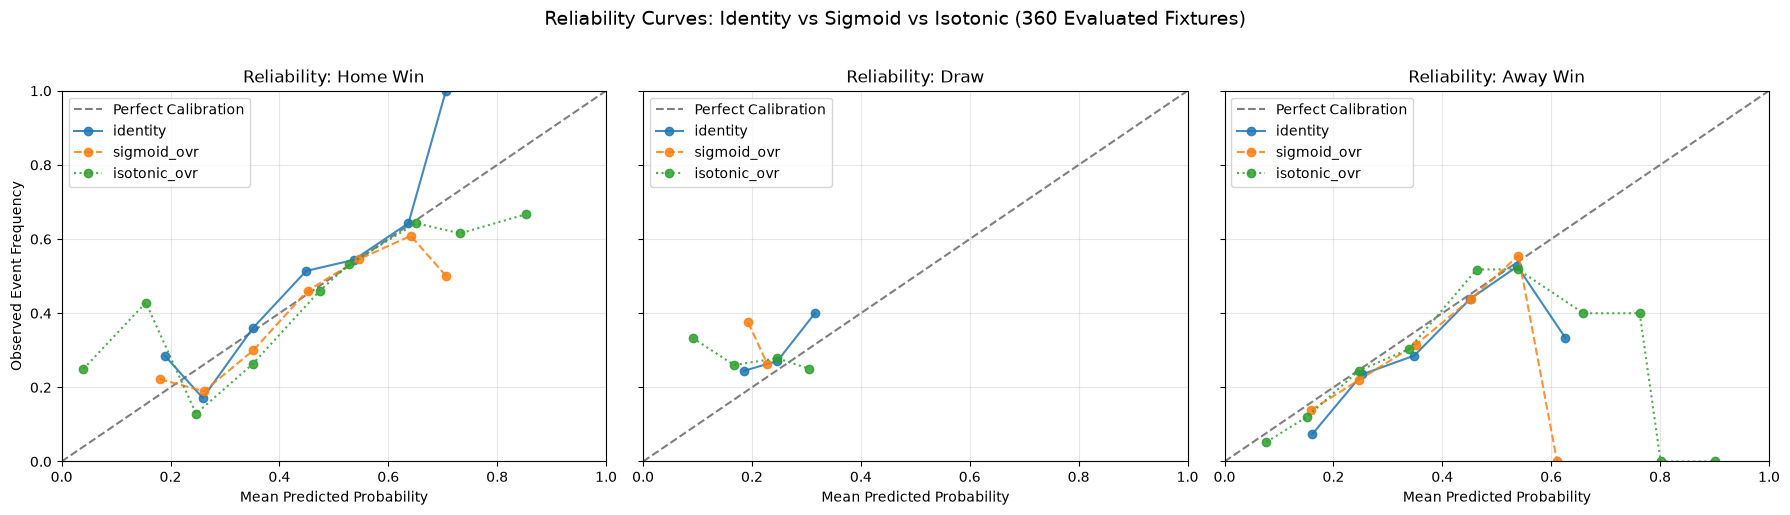

Reliability Bins with Samples (Identity):


,class_label,bin_index,bin_lower,bin_upper,fixture_count,mean_predicted_probability,observed_frequency,absolute_calibration_gap
1,home_win,1,0.1,0.2,7,0.189382,0.285714,0.096332
2,home_win,2,0.2,0.3,70,0.259308,0.171429,0.087879
3,home_win,3,0.3,0.4,89,0.351076,0.359551,0.008474
4,home_win,4,0.4,0.5,107,0.449108,0.514019,0.064910
5,home_win,5,0.5,0.6,57,0.536815,0.543860,0.007045
6,home_win,6,0.6,0.7,28,0.637057,0.642857,0.005800
7,home_win,7,0.7,0.8,2,0.705843,1.000000,0.294157
11,draw,1,0.1,0.2,45,0.185120,0.244444,0.059325
12,draw,2,0.2,0.3,295,0.246848,0.271186,0.024339
13,draw,3,0.3,0.4,20,0.315633,0.400000,0.084367


In [6]:
# NBVAL_IGNORE_OUTPUT
reliability_df = compute_recalibration_reliability(
    forward_preds,
    n_bins=int(recal_config.get("reliability_bins_per_class", 10)),
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
colors = {"identity": "#1f77b4", "sigmoid_ovr": "#ff7f0e", "isotonic_ovr": "#2ca02c"}
styles = {"identity": "-", "sigmoid_ovr": "--", "isotonic_ovr": ":"}

for idx, (class_idx, class_label) in enumerate(CLASS_LABELS.items()):
    ax = axes[idx]
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfect Calibration")
    
    for method in methods:
        sub = reliability_df[
            (reliability_df["calibration_method"] == method) &
            (reliability_df["class_index"] == class_idx) &
            (reliability_df["fixture_count"] > 0)
        ]
        ax.plot(
            sub["mean_predicted_probability"],
            sub["observed_frequency"],
            marker="o",
            linestyle=styles[method],
            color=colors[method],
            label=f"{method}",
            alpha=0.85,
        )
    
    ax.set_title(f"Reliability: {class_label.replace('_', ' ').title()}")
    ax.set_xlabel("Mean Predicted Probability")
    if idx == 0:
        ax.set_ylabel("Observed Event Frequency")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")

plt.suptitle("Reliability Curves: Identity vs Sigmoid vs Isotonic (360 Evaluated Fixtures)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Display bin counts and gaps for sparse bin inspection
print("Reliability Bins with Samples (Identity):")
display(reliability_df[(reliability_df["calibration_method"] == "identity") & (reliability_df["fixture_count"] > 0)][
    ["class_label", "bin_index", "bin_lower", "bin_upper", "fixture_count", "mean_predicted_probability", "observed_frequency", "absolute_calibration_gap"]
])


## 7. Chronological Stability & Fold-Level Paired Deltas

We inspect:
1. Fold-level paired Brier score deltas relative to `identity`.
2. Fold-level paired Log-loss deltas relative to `identity`.
3. Monthly chronological Brier score trend comparing raw probabilities against the candidate methods on identical forward-evaluated fixtures.


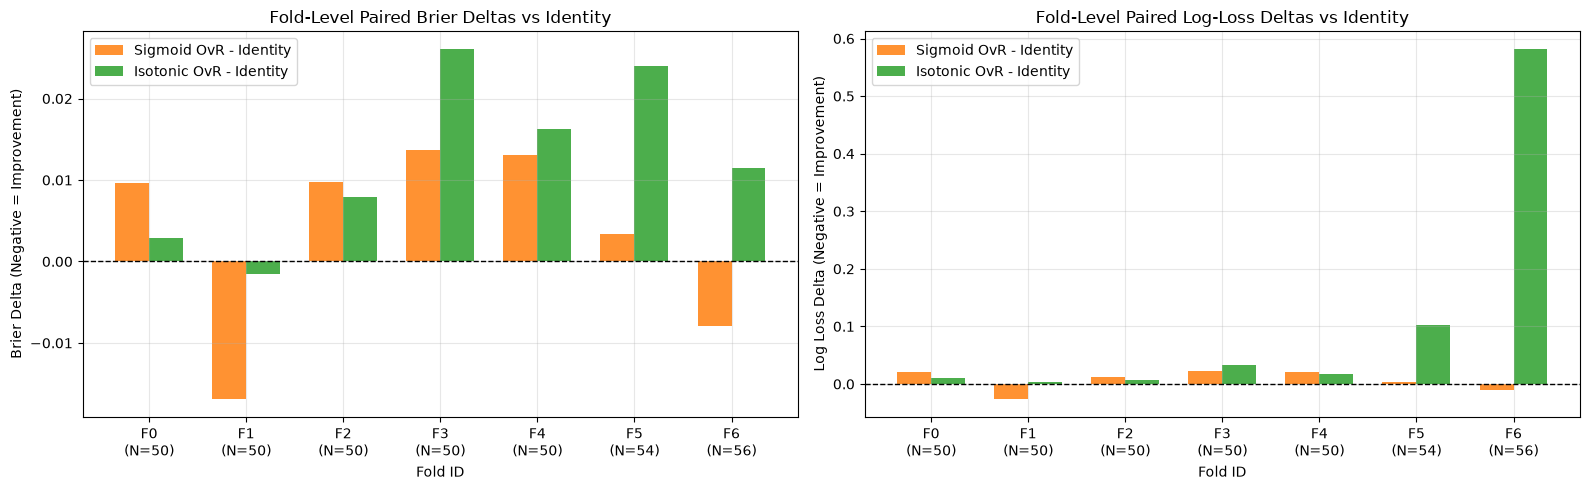

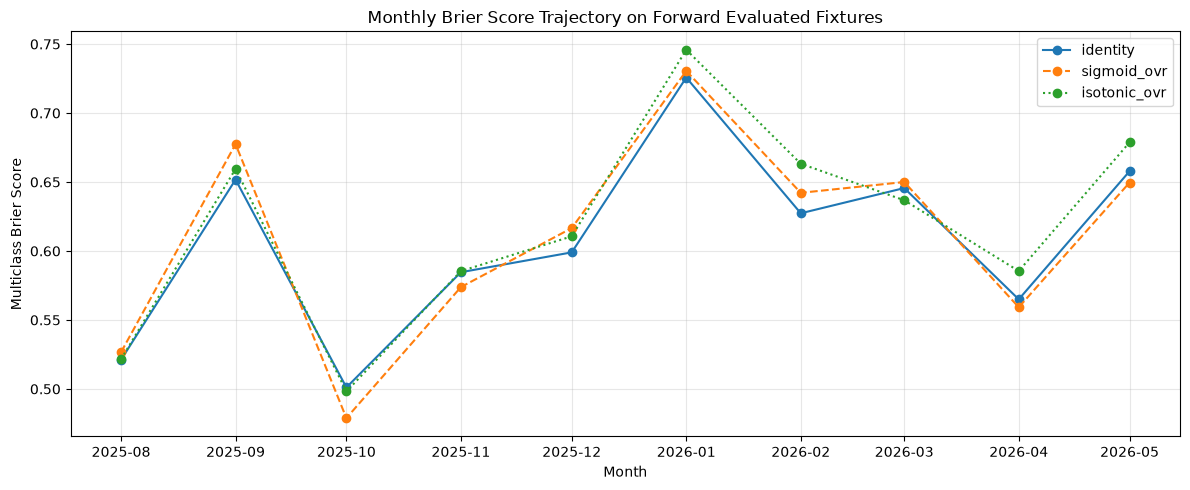

In [7]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Fold Brier Deltas
id_folds = fold_metrics[fold_metrics["calibration_method"] == "identity"].set_index("fold_id")
sig_folds = fold_metrics[fold_metrics["calibration_method"] == "sigmoid_ovr"].set_index("fold_id")
iso_folds = fold_metrics[fold_metrics["calibration_method"] == "isotonic_ovr"].set_index("fold_id")

fold_indices = np.arange(len(id_folds))
width = 0.35

brier_delta_sig = sig_folds["multiclass_brier_score"] - id_folds["multiclass_brier_score"]
brier_delta_iso = iso_folds["multiclass_brier_score"] - id_folds["multiclass_brier_score"]

ax1 = axes[0]
ax1.bar(fold_indices - width/2, brier_delta_sig, width, label="Sigmoid OvR - Identity", color="#ff7f0e", alpha=0.85)
ax1.bar(fold_indices + width/2, brier_delta_iso, width, label="Isotonic OvR - Identity", color="#2ca02c", alpha=0.85)
ax1.axhline(0, color="black", linestyle="--", linewidth=1)
ax1.set_xlabel("Fold ID")
ax1.set_ylabel("Brier Delta (Negative = Improvement)")
ax1.set_title("Fold-Level Paired Brier Deltas vs Identity")
ax1.set_xticks(fold_indices)
ax1.set_xticklabels([f"F{i}\n(N={id_folds.loc[i, 'eval_count']})" for i in fold_indices])
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Fold Log Loss Deltas
ll_delta_sig = sig_folds["log_loss"] - id_folds["log_loss"]
ll_delta_iso = iso_folds["log_loss"] - id_folds["log_loss"]

ax2 = axes[1]
ax2.bar(fold_indices - width/2, ll_delta_sig, width, label="Sigmoid OvR - Identity", color="#ff7f0e", alpha=0.85)
ax2.bar(fold_indices + width/2, ll_delta_iso, width, label="Isotonic OvR - Identity", color="#2ca02c", alpha=0.85)
ax2.axhline(0, color="black", linestyle="--", linewidth=1)
ax2.set_xlabel("Fold ID")
ax2.set_ylabel("Log Loss Delta (Negative = Improvement)")
ax2.set_title("Fold-Level Paired Log-Loss Deltas vs Identity")
ax2.set_xticks(fold_indices)
ax2.set_xticklabels([f"F{i}\n(N={id_folds.loc[i, 'eval_count']})" for i in fold_indices])
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

# Monthly Trend on identical forward-evaluated rows
monthly_records = []
forward_preds["month"] = forward_preds["date"].dt.to_period("M")

for (method, month), grp in forward_preds.groupby(["calibration_method", "month"], sort=True):
    p = grp[["calibrated_prob_home_win", "calibrated_prob_draw", "calibrated_prob_away_win"]].to_numpy()
    y = grp["target_encoded"].to_numpy()
    monthly_records.append({
        "calibration_method": method,
        "month": month.to_timestamp(),
        "fixture_count": len(grp),
        "brier_score": multiclass_brier_score(p, y),
        "log_loss": multiclass_log_loss(p, y),
    })

monthly_df = pd.DataFrame(monthly_records)

plt.figure(figsize=(12, 5))
for method in methods:
    m_sub = monthly_df[monthly_df["calibration_method"] == method]
    plt.plot(m_sub["month"], m_sub["brier_score"], marker="o", label=method, linestyle=styles[method], color=colors[method])

plt.xlabel("Month")
plt.ylabel("Multiclass Brier Score")
plt.title("Monthly Brier Score Trajectory on Forward Evaluated Fixtures")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Select Method or Retain Raw Probabilities

We review the formal selection decision based on the conservative provisional adoption criteria:


In [8]:
print(f"Selected Recalibration Method: {selected_method.upper()}")
if selected_method == "identity":
    print("Decision: RETAIN RAW ENSEMBLE PROBABILITIES (No Recalibration).")
    print("Rationale: Neither sigmoid nor isotonic recalibration improved pooled Brier score or achieved consistent fold-level wins.")
else:
    print(f"Decision: ADOPT {selected_method.upper()} RECALIBRATION.")

for _, row in comp_df.iterrows():
    m = row["calibration_method"]
    status = "SELECTED" if row["is_selected_method"] else ("REJECTED" if m != "identity" else "BASELINE")
    print(f"  [{status:8s}] {m:14s}: Pooled Brier={row['multiclass_brier_score']:.6f} (Delta={row['brier_delta']:+.6f}), "
          f"Log Loss={row['log_loss']:.6f} (Delta={row['log_loss_delta']:+.6f}), "
          f"Fold Wins={row['fold_brier_win_count']}/{row['fold_count']}, "
          f"Eligibility: {row['rejection_reason']}")


Selected Recalibration Method: IDENTITY
Decision: RETAIN RAW ENSEMBLE PROBABILITIES (No Recalibration).
Rationale: Neither sigmoid nor isotonic recalibration improved pooled Brier score or achieved consistent fold-level wins.
  [SELECTED] identity      : Pooled Brier=0.620044 (Delta=+0.000000), Log Loss=1.032383 (Delta=+0.000000), Fold Wins=0/7, Eligibility: baseline_method
  [REJECTED] sigmoid_ovr   : Pooled Brier=0.623390 (Delta=+0.003345), Log Loss=1.038297 (Delta=+0.005914), Fold Wins=2/7, Eligibility: did not improve pooled Brier (+0.003345 >= -1e-12); worsened pooled log-loss (+0.005914 > 1e-12); won only 2/7 folds (<= 50%)
  [REJECTED] isotonic_ovr  : Pooled Brier=0.632600 (Delta=+0.012555), Log Loss=1.148308 (Delta=+0.115926), Fold Wins=1/7, Eligibility: did not improve pooled Brier (+0.012555 >= -1e-12); worsened pooled log-loss (+0.115926 > 1e-12); won only 1/7 folds (<= 50%)


## 9. Save and Verify Evaluation Artifacts

We save all five Task 5.2 artifacts to `data/processed/` and verify that:
1. `recalibration_fold_metrics.parquet`: Per-fold metrics for each method.
2. `recalibration_comparison.parquet`: Overall pooled comparisons and selected candidate.
3. `recalibration_reliability_data.parquet`: Complete 10-bin reliability tables.
4. `recalibration_forward_predictions.parquet`: Forward predictions for all methods.
5. `recalibrated_probabilities.parquet`: Selected method's predictions (calibrated columns match raw columns if identity is selected).
6. Saved predictions reproduce the reported metrics and contain valid probability simplex rows.


In [9]:
saved_paths = save_recalibration_artifacts(
    fold_metrics=fold_metrics,
    comparison=comp_df,
    reliability_data=reliability_df,
    forward_predictions=forward_preds,
    selected_method=selected_method,
    output_dir=processed_dir,
)

print("Saved artifacts:")
for k, path in saved_paths.items():
    assert path.exists(), f"Missing artifact: {path}"
    df_check = pd.read_parquet(path)
    print(f"  {k:28s}: {path.name:45s} ({len(df_check):4d} rows, {len(df_check.columns):2d} cols)")

# Verify metric reproduction
recal_saved = pd.read_parquet(saved_paths["recalibrated_probabilities"])
p_saved = recal_saved[["calibrated_prob_home_win", "calibrated_prob_draw", "calibrated_prob_away_win"]].to_numpy()
y_saved = recal_saved["target_encoded"].to_numpy()

reproduced_brier = multiclass_brier_score(p_saved, y_saved)
reproduced_ll = multiclass_log_loss(p_saved, y_saved)
reproduced_acc = classification_accuracy(p_saved, y_saved)

target_row = comp_df[comp_df["calibration_method"] == selected_method].iloc[0]
assert np.isclose(reproduced_brier, target_row["multiclass_brier_score"], atol=1e-12)
assert np.isclose(reproduced_ll, target_row["log_loss"], atol=1e-12)
assert np.isclose(reproduced_acc, target_row["accuracy"], atol=1e-12)
print("\nAll saved artifacts successfully verified and reproduce reported metrics exactly.")


Saved artifacts:
  fold_metrics                : recalibration_fold_metrics.parquet            (  21 rows, 15 cols)
  comparison                  : recalibration_comparison.parquet              (   3 rows, 22 cols)
  reliability_data            : recalibration_reliability_data.parquet        (  90 rows, 12 cols)
  forward_predictions         : recalibration_forward_predictions.parquet     (1080 rows, 16 cols)
  recalibrated_probabilities  : recalibrated_probabilities.parquet            ( 360 rows, 16 cols)

All saved artifacts successfully verified and reproduce reported metrics exactly.


## 10. Limitations and Next Action

### Key Findings & Limitations
1. **Conditional Evaluation:** The 80/20 ensemble weights were previously selected across the full 560-fixture OOF set in Task 4.3. The temporal recalibration evaluation conducted here is conditional on that chosen blend. It is not an untouched end-to-end pipeline evaluation.
2. **Post-Hoc Fitting Ineffective on Small Samples:** Calibrator fitting windows ranged from 200 to 504 matches. On these sample sizes, parametric Platt scaling (sigmoid) and non-parametric isotonic regression introduced variance and overfitted calibration training subsets, leading to worse out-of-fold generalization on subsequent fixtures (Brier `0.6234` and `0.6326` vs raw `0.6200`).
3. **Conservative Adoption Outcome:** Because neither calibrator improved pooled Brier or achieved majority fold wins, the conservative selection protocol retains **`identity`** (raw ensemble probabilities).
4. **Next Step:** Proceed to **Phase 6: Betting Simulation & Value Engine**, ingesting market closing odds and testing value thresholding using the validated probabilities.
